In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rcParams
from narwhals import corr

rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang SC", "Heiti TC", "Arial", 'Times New Roman'] # 中文字体优先，解决中文显示问题
rcParams["axes.unicode_minus"] = False  # 解决负号显示问题（原有，保留
from pathlib import Path
import pandas as pd
source_path  = Path.cwd().parent / "资料-pd"

df = pd.read_csv(source_path / "house_sales.csv")
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long
0,1,2005-10-24,476315.91,8,4,1921,1856,3,0,0,3,7,1864,87,1979,2010,98001,47.341860,-122.183176
1,2,1937-07-18,698980.64,4,4,1503,6659,2,0,1,1,7,2177,100,1937,0,98010,47.532967,-122.026116
2,3,2008-08-01,663024.75,3,3,3494,3112,2,0,3,4,12,2030,1084,1968,1989,98006,47.345444,-121.635418
3,4,2011-08-31,629698.77,8,1,2618,8264,1,0,2,4,7,1576,1108,1911,1999,98010,47.749573,-121.794627
4,5,2011-02-26,658139.54,1,2,1661,3386,1,0,3,3,2,517,816,1900,0,98001,47.737984,-121.701806


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             10000 non-null  int64  
 1   date           10000 non-null  str    
 2   price          10000 non-null  float64
 3   bedrooms       10000 non-null  int64  
 4   bathrooms      10000 non-null  int64  
 5   sqft_living    10000 non-null  int64  
 6   sqft_lot       10000 non-null  int64  
 7   floors         10000 non-null  int64  
 8   waterfront     10000 non-null  int64  
 9   view           10000 non-null  int64  
 10  condition      10000 non-null  int64  
 11  grade          10000 non-null  int64  
 12  sqft_above     10000 non-null  int64  
 13  sqft_basement  10000 non-null  int64  
 14  yr_built       10000 non-null  int64  
 15  yr_renovated   10000 non-null  int64  
 16  zipcode        10000 non-null  int64  
 17  lat            10000 non-null  float64
 18  long           100

In [4]:
# 查看没列的缺损值情况
df.isnull().sum()


id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
dtype: int64

In [6]:
# 丢弃缺失值
df.dropna()


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long
0,1,2005-10-24,476315.91,8,4,1921,1856,3,0,0,3,7,1864,87,1979,2010,98001,47.341860,-122.183176
1,2,1937-07-18,698980.64,4,4,1503,6659,2,0,1,1,7,2177,100,1937,0,98010,47.532967,-122.026116
2,3,2008-08-01,663024.75,3,3,3494,3112,2,0,3,4,12,2030,1084,1968,1989,98006,47.345444,-121.635418
3,4,2011-08-31,629698.77,8,1,2618,8264,1,0,2,4,7,1576,1108,1911,1999,98010,47.749573,-121.794627
4,5,2011-02-26,658139.54,1,2,1661,3386,1,0,3,3,2,517,816,1900,0,98001,47.737984,-121.701806
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,1953-07-11,303685.99,3,2,2378,6259,1,0,4,4,13,2398,450,1927,1992,98010,47.394280,-121.689675
9996,9997,2016-01-03,336882.94,2,1,4837,6226,2,1,2,1,8,2198,1567,1986,2006,98003,47.530260,-122.444554
9997,9998,2021-11-12,423961.29,4,4,4750,1641,2,1,1,2,1,2442,380,2018,0,98004,47.020433,-122.275511
9998,9999,1969-09-03,394782.02,6,5,4108,7847,1,0,4,3,1,4226,1899,1912,0,98001,47.034089,-122.122351


In [9]:
# 异常值检查 使用IOR方法  #房价为例
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
IQR


np.float64(135393.20749999996)

In [11]:
lower_bound = Q1 - 1.5 * IQR # 下界
upper_bound = Q3 + 1.5 * IQR # 上界
df = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]
df.shape
df


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long
0,1,2005-10-24,476315.91,8,4,1921,1856,3,0,0,3,7,1864,87,1979,2010,98001,47.341860,-122.183176
1,2,1937-07-18,698980.64,4,4,1503,6659,2,0,1,1,7,2177,100,1937,0,98010,47.532967,-122.026116
2,3,2008-08-01,663024.75,3,3,3494,3112,2,0,3,4,12,2030,1084,1968,1989,98006,47.345444,-121.635418
3,4,2011-08-31,629698.77,8,1,2618,8264,1,0,2,4,7,1576,1108,1911,1999,98010,47.749573,-121.794627
4,5,2011-02-26,658139.54,1,2,1661,3386,1,0,3,3,2,517,816,1900,0,98001,47.737984,-121.701806
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,1953-07-11,303685.99,3,2,2378,6259,1,0,4,4,13,2398,450,1927,1992,98010,47.394280,-121.689675
9996,9997,2016-01-03,336882.94,2,1,4837,6226,2,1,2,1,8,2198,1567,1986,2006,98003,47.530260,-122.444554
9997,9998,2021-11-12,423961.29,4,4,4750,1641,2,1,1,2,1,2442,380,2018,0,98004,47.020433,-122.275511
9998,9999,1969-09-03,394782.02,6,5,4108,7847,1,0,4,3,1,4226,1899,1912,0,98001,47.034089,-122.122351


In [12]:
#数据类型的转换
df["date"] = pd.to_datetime(df["date"])


In [13]:
# 增加房屋的使用年限
df["usage_years"] = df["date"].dt.year - df["yr_built"]
df.head()


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,usage_years
0,1,2005-10-24,476315.91,8,4,1921,1856,3,0,0,3,7,1864,87,1979,2010,98001,47.341860,-122.183176,26
1,2,1937-07-18,698980.64,4,4,1503,6659,2,0,1,1,7,2177,100,1937,0,98010,47.532967,-122.026116,0
2,3,2008-08-01,663024.75,3,3,3494,3112,2,0,3,4,12,2030,1084,1968,1989,98006,47.345444,-121.635418,40
3,4,2011-08-31,629698.77,8,1,2618,8264,1,0,2,4,7,1576,1108,1911,1999,98010,47.749573,-121.794627,100
4,5,2011-02-26,658139.54,1,2,1661,3386,1,0,3,3,2,517,816,1900,0,98001,47.737984,-121.701806,111


In [16]:
# 增加是翻新
df["renovated"] = df["yr_renovated"].apply(lambda x: 1 if x > 0 else 0)
df.head(1)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,usage_years,renovated
0,1,2005-10-24,476315.91,8,4,1921,1856,3,0,0,...,7,1864,87,1979,2010,98001,47.34186,-122.183176,26,1


In [18]:
# 选择数值类型的
numeric_columns = df.select_dtypes(include=[np.number]).columns
numeric_columns

Index(['id', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',
       'usage_years', 'renovated'],
      dtype='str')

In [20]:
# 计算描述统计信息
df[numeric_columns].describe(percentiles=[0.25, 0.75])


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,usage_years,renovated
count,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000,9930.000000
mean,5001.107049,501121.772151,4.496878,3.521349,2906.238671,5520.495065,1.999295,0.498489,2.016314,2.985901,7.018228,2522.702820,999.519335,1962.178046,589.065861,98005.529607,47.400335,-122.095249,30.845015,0.295569
std,2885.966447,97124.951211,2.297853,1.727304,1210.034706,2604.054446,0.819431,0.500023,1.418670,1.416136,3.746011,1153.480058,576.428275,36.079476,909.566829,2.884171,0.231491,0.289912,27.518804,0.456321
min,1.000000,229983.900000,1.000000,1.000000,801.000000,1000.000000,1.000000,0.000000,0.000000,1.000000,1.000000,500.000000,0.000000,1900.000000,0.000000,98001.000000,47.000216,-122.599943,0.000000,0.000000
25%,2503.250000,433529.705000,2.000000,2.000000,1865.000000,3281.250000,1.000000,0.000000,1.000000,2.000000,4.000000,1527.000000,503.250000,1931.000000,0.000000,98003.000000,47.200889,-122.344499,8.000000,0.000000
75%,7496.750000,567653.252500,7.000000,5.000000,3957.000000,7802.000000,3.000000,1.000000,3.000000,4.000000,10.000000,3538.000000,1501.750000,1993.000000,1962.000000,98008.000000,47.603980,-121.843351,48.000000,1.000000
max,10000.000000,770223.220000,8.000000,6.000000,5000.000000,10000.000000,3.000000,1.000000,4.000000,5.000000,13.000000,4500.000000,2000.000000,2024.000000,2024.000000,98010.000000,47.799975,-121.600304,124.000000,1.000000


In [22]:
# 相关性统计
corr = df[numeric_columns].corr()
corr

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,usage_years,renovated
id,1.000000,0.011216,-0.006440,-0.008188,0.013003,0.005122,-0.005166,0.003387,0.024856,0.010594,-0.009443,-0.008562,-0.014837,-0.004851,-0.020986,-0.009722,0.003481,-0.002111,-0.005287,-0.021113
price,0.011216,1.000000,0.004881,0.008096,0.011616,0.003644,-0.005926,0.001748,-0.002817,0.001813,0.004603,-0.005068,-0.003476,0.012998,-0.000186,0.007931,-0.001472,-0.006436,-0.004177,-0.000069
bedrooms,-0.006440,0.004881,1.000000,-0.002343,-0.020059,0.021208,0.017998,-0.004694,0.003970,-0.000787,-0.013361,0.022470,0.009226,0.009836,-0.006390,0.012080,-0.002665,-0.002841,-0.006008,-0.006468
bathrooms,-0.008188,0.008096,-0.002343,1.000000,0.007319,-0.002151,-0.014185,0.005635,-0.002403,0.011281,-0.016240,0.018340,-0.005133,0.005728,0.003120,0.011103,0.000083,0.015726,-0.009371,0.003046
sqft_living,0.013003,0.011616,-0.020059,0.007319,1.000000,0.000223,-0.005063,-0.026771,0.000965,-0.009645,-0.010953,-0.010732,0.026800,0.018514,0.008230,-0.004238,0.002503,-0.001800,-0.006160,0.008152
sqft_lot,0.005122,0.003644,0.021208,-0.002151,0.000223,1.000000,0.011353,0.017745,-0.002272,0.021365,-0.017282,0.009031,0.007044,-0.013037,-0.005570,-0.003720,0.017905,-0.003339,-0.000940,-0.005550
floors,-0.005166,-0.005926,0.017998,-0.014185,-0.005063,0.011353,1.000000,0.031829,-0.012899,0.012489,-0.000816,0.008511,0.008378,0.015004,0.009454,-0.011092,-0.006356,-0.002881,-0.017750,0.009446
waterfront,0.003387,0.001748,-0.004694,0.005635,-0.026771,0.017745,0.031829,1.000000,-0.013595,0.005801,-0.015498,0.005548,0.004903,0.000406,-0.006734,-0.020082,0.010025,-0.002210,0.005542,-0.006650
view,0.024856,-0.002817,0.003970,-0.002403,0.000965,-0.002272,-0.012899,-0.013595,1.000000,0.000616,0.011258,-0.014169,0.011199,-0.014928,-0.002599,0.008103,0.025792,-0.002236,0.005635,-0.002471
condition,0.010594,0.001813,-0.000787,0.011281,-0.009645,0.021365,0.012489,0.005801,0.000616,1.000000,0.004985,0.014193,-0.001213,-0.002500,-0.009889,-0.010822,0.005663,0.008908,0.003324,-0.009604


In [29]:
print(corr['price'] > 0) # 多少才算正相关

id                True
price             True
bedrooms          True
bathrooms         True
sqft_living       True
sqft_lot          True
floors           False
waterfront        True
view             False
condition         True
grade             True
sqft_above       False
sqft_basement    False
yr_built          True
yr_renovated     False
zipcode           True
lat              False
long             False
usage_years      False
renovated        False
Name: price, dtype: bool


In [34]:
# 邮政编码分组
df.groupby("zipcode").agg(
    {
        "price": ["mean", "median", "std"],
        "sqft_living": ["mean", "median", "std"],
        'bedrooms': "mean",
    }
)

price                             sqft_living          \
                  mean      median            std         mean  median   
zipcode                                                                  
98001    502211.909176  505563.480   95027.086877  2917.520854  2941.0   
98002    497808.793483  498809.820  103854.575502  2955.262821  3044.0   
98003    497930.512592  499140.600   95406.075080  2870.403689  2832.0   
98004    498747.163954  496565.515   93464.563915  2857.314854  2866.5   
98005    503306.661532  503289.415   95707.568429  2975.695481  3013.0   
98006    505345.428558  508340.710  100038.154028  2887.992944  2892.0   
98007    502716.775391  502867.080   96360.190007  2900.131553  2830.0   
98008    499171.818208  501030.100   96897.606393  2877.518519  2849.0   
98009    500330.593340  499959.910   95953.881794  2901.382627  2947.0   
98010    503083.699933  499410.160   98519.997803  2916.949234  2890.0   

                      bedrooms  
                 std      mean  
zipcode                         
98001    1203.872716  4.357905  
98002    1192.657653  4.554487  
98003    1243.977493  4.547131  
98004    1195.500580  4.407950  
98005    1210.770225  4.548134  
98006    1188.076527  4.599798  
98007    1216.858540  4.358061  
98008    1231.128377  4.499499  
98009    1213.582323  4.472596  
98010    1202.681106  4.623563

In [42]:
renovation_stats = df.groupby('renovated').agg({
 'price': 'mean',
 'sqft_living': 'mean',
 'bedrooms': 'mean'
})
renovation_stats.columns = ['mean_price', 'mean_sqft_living', 'mean_bedrooms']
renovation_stats



,mean_price,mean_sqft_living,mean_bedrooms
renovated,,,
0,501126.095841,2899.849035,4.506505
1,501111.467479,2921.467121,4.473935


In [45]:
# 按照房龄分组
df["age_group"] = pd.cut(df["usage_years"], bins=5)
df

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,usage_years,renovated,age_group
0,1,2005-10-24,476315.91,8,4,1921,1856,3,0,0,...,1864,87,1979,2010,98001,47.341860,-122.183176,26,1,"(24.8, 49.6]"
1,2,1937-07-18,698980.64,4,4,1503,6659,2,0,1,...,2177,100,1937,0,98010,47.532967,-122.026116,0,0,"(-0.124, 24.8]"
2,3,2008-08-01,663024.75,3,3,3494,3112,2,0,3,...,2030,1084,1968,1989,98006,47.345444,-121.635418,40,1,"(24.8, 49.6]"
3,4,2011-08-31,629698.77,8,1,2618,8264,1,0,2,...,1576,1108,1911,1999,98010,47.749573,-121.794627,100,1,"(99.2, 124.0]"
4,5,2011-02-26,658139.54,1,2,1661,3386,1,0,3,...,517,816,1900,0,98001,47.737984,-121.701806,111,0,"(99.2, 124.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,1953-07-11,303685.99,3,2,2378,6259,1,0,4,...,2398,450,1927,1992,98010,47.394280,-121.689675,26,1,"(24.8, 49.6]"
9996,9997,2016-01-03,336882.94,2,1,4837,6226,2,1,2,...,2198,1567,1986,2006,98003,47.530260,-122.444554,30,1,"(24.8, 49.6]"
9997,9998,2021-11-12,423961.29,4,4,4750,1641,2,1,1,...,2442,380,2018,0,98004,47.020433,-122.275511,3,0,"(-0.124, 24.8]"
9998,9999,1969-09-03,394782.02,6,5,4108,7847,1,0,4,...,4226,1899,1912,0,98001,47.034089,-122.122351,57,0,"(49.6, 74.4]"


In [46]:
#平均每年房价
df.groupby(df["date"].dt.year).agg({"price": "mean"})


,price
date,
1900,488884.680000
1902,513972.100000
1903,509519.793333
1905,522640.340000
1906,470978.868333
...,...
2020,512492.021111
2021,494507.942625
2022,498970.821277


In [48]:
# 不同翻新情况的房价

In [50]:
df.groupby([df["date"].dt.year, 'renovated'])['price'].mean()


date  renovated
1900  0            488884.680000
1902  0            513972.100000
1903  0            445335.310000
      1            637888.760000
1905  0            522640.340000
                       ...      
2022  1            484070.180990
2023  0            502393.039380
      1            502439.298437
2024  0            497149.856014
      1            505383.902403
Name: price, Length: 240, dtype: float64

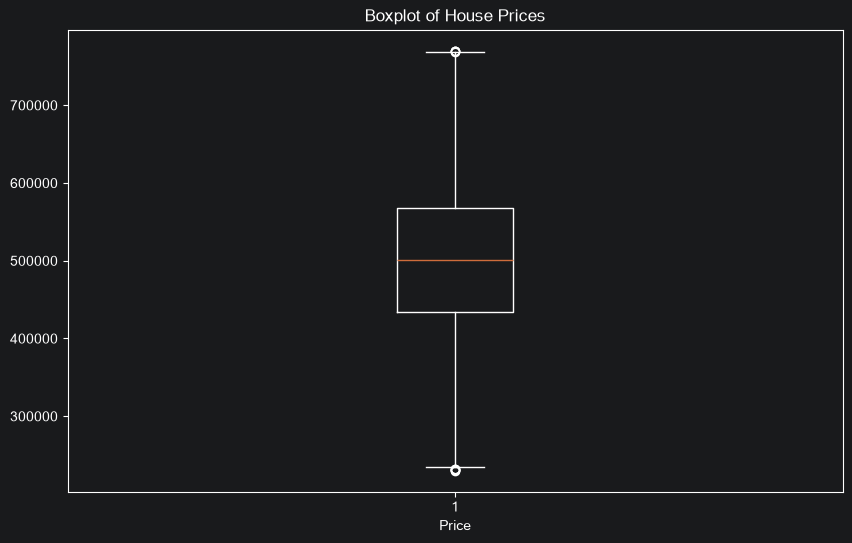

In [52]:
# 可视化
plt.figure(figsize=(10, 6))
plt.boxplot(df["price"])
plt.title("Boxplot of House Prices")
plt.xlabel("Price")
plt.show()


